# Project 3: Multi-view Breast Cancer Detection Using Mammography

# 1. Data Exploration and Preparation

This notebook investigates the VinDr-Mammo dataset, examines class distributions and mammographic views, constructs paired CC/MLO samples, and prepares leakage-resistant training, validation, and test partitions.

## 1.1 Dataset Overview

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

A fixed random seed is used to improve experiment reproducibility.
The same seed will be reused when possible in later experiments.

In [ ]:
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = Path(PROJECT_DIR / "data")

breast_df = pd.read_csv(DATA_DIR / "breast-level_annotations.csv")
finding_df = pd.read_csv(DATA_DIR / "finding_annotations.csv")
metadata_df = pd.read_csv(DATA_DIR / "metadata.csv")

In [4]:
print("Breast-level annotations:", breast_df.shape)
print("Finding annotations:", finding_df.shape)
print("Metadata:", metadata_df.shape)

Breast-level annotations: (20000, 10)
Finding annotations: (20486, 16)
Metadata: (20000, 21)


In [5]:
breast_df.head()

,study_id,series_id,image_id,laterality,view_position,height,width,breast_birads,breast_density,split
0,b8d273e8601f348d3664778dae0e7e0b,b36517b9cbbcfd286a7ae04f643af97a,d8125545210c08e1b1793a5af6458ee2,L,CC,3518,2800,BI-RADS 2,DENSITY C,training
1,b8d273e8601f348d3664778dae0e7e0b,b36517b9cbbcfd286a7ae04f643af97a,290c658f4e75a3f83ec78a847414297c,L,MLO,3518,2800,BI-RADS 2,DENSITY C,training
2,b8d273e8601f348d3664778dae0e7e0b,b36517b9cbbcfd286a7ae04f643af97a,cd0fc7bc53ac632a11643ac4cc91002a,R,CC,3518,2800,BI-RADS 2,DENSITY C,training
3,b8d273e8601f348d3664778dae0e7e0b,b36517b9cbbcfd286a7ae04f643af97a,71638b1e853799f227492bfb08a01491,R,MLO,3518,2800,BI-RADS 2,DENSITY C,training
4,8269f5971eaca3e5d3772d1796e6bd7a,d931832a0815df082c085b6e09d20aac,dd9ce3288c0773e006a294188aadba8e,L,CC,3518,2800,BI-RADS 1,DENSITY C,training


In [6]:
print("Number of images:", breast_df["image_id"].nunique())
print("Number of studies:", breast_df["study_id"].nunique())

Number of images: 20000
Number of studies: 5000


## 1.2 Mammographic Views and Laterality

In [7]:
images_per_study = breast_df.groupby("study_id").size()

images_per_study.value_counts()

4    5000
Name: count, dtype: int64

Each study contains four mammographic images.

Typically, these correspond to:

- Left CC
- Left MLO
- Right CC
- Right MLO

This structure makes the dataset suitable for multi-view learning.

In [8]:
breast_df["view_position"].value_counts()

view_position
CC     10001
MLO     9999
Name: count, dtype: int64

The nearly equal number of CC and MLO images suggests that paired multi-view analysis should be feasible.

In [9]:
breast_df["laterality"].value_counts()

laterality
L    10000
R    10000
Name: count, dtype: int64

The dataset contains an equal number of left and right breast images.

## 1.3 BI-RADS distribution

BI-RADS categories represent increasing levels of radiological suspicion, from normal findings to highly suspicious abnormalities.

In [10]:
birads_counts = breast_df["breast_birads"].value_counts().sort_index()

birads_counts

breast_birads
BI-RADS 1    13406
BI-RADS 2     4676
BI-RADS 3      930
BI-RADS 4      762
BI-RADS 5      226
Name: count, dtype: int64

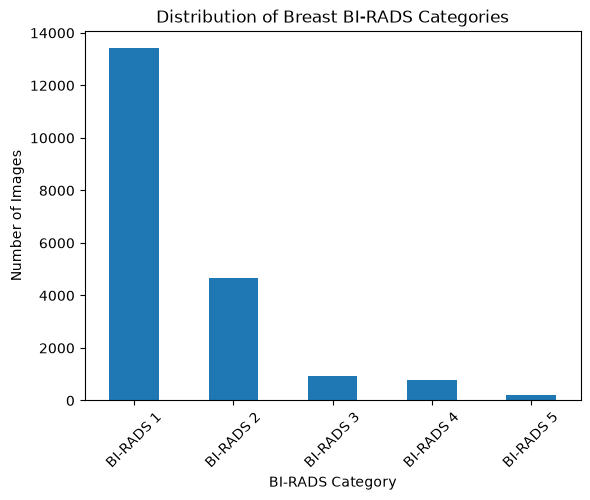

In [11]:
birads_counts.plot(kind="bar")

plt.title("Distribution of Breast BI-RADS Categories")
plt.xlabel("BI-RADS Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [12]:
birads_percent = (
    breast_df["breast_birads"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

birads_percent.round(2)

breast_birads
BI-RADS 1    67.03
BI-RADS 2    23.38
BI-RADS 3     4.65
BI-RADS 4     3.81
BI-RADS 5     1.13
Name: proportion, dtype: float64

The BI-RADS distribution is strongly imbalanced, with BI-RADS 1 and
BI-RADS 2 representing the majority of images, while BI-RADS 4 and
BI-RADS 5 are substantially less common.

This imbalance must be considered during model training and motivates
the later comparison of BCE, weighted BCE and focal loss.

## 1.4 Breast density

In [13]:
density_counts = breast_df["breast_density"].value_counts().sort_index()

density_counts

breast_density
DENSITY A      100
DENSITY B     1908
DENSITY C    15292
DENSITY D     2700
Name: count, dtype: int64

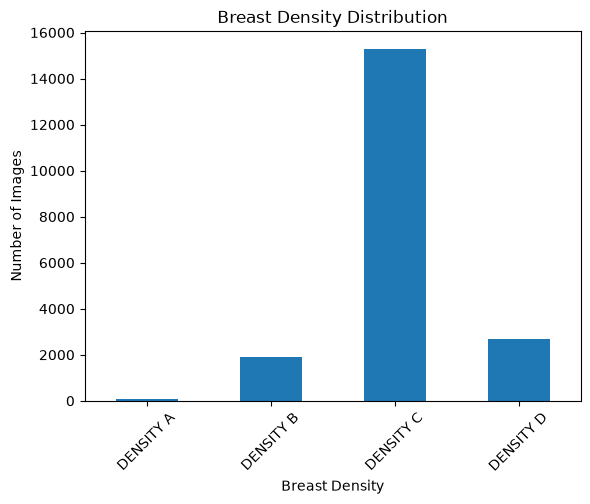

In [14]:
density_counts.plot(kind="bar")

plt.title("Breast Density Distribution")
plt.xlabel("Breast Density")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

Most images belong to density category C, indicating that the dataset is not evenly distributed across breast-density groups.

## 1.5 Official Dataset Split

In [15]:
print(breast_df["split"].value_counts())
print("\n")
print(breast_df.groupby("split")["study_id"].nunique())

split
training    16000
test         4000
Name: count, dtype: int64


split
test        1000
training    4000
Name: study_id, dtype: int64


The dataset provides an official training/test split consisting of
4,000 training studies and 1,000 test studies.

The official test set will be preserved and will not be used for
model selection or hyperparameter tuning.

In [16]:
view_pairs = (
    breast_df
    .groupby(["study_id", "laterality"])["view_position"]
    .agg(lambda x: set(x))
)

view_pairs.head()

study_id                          laterality
0025a5dc99fd5c742026f0b2b030d3e9  L             {MLO, CC}
                                  R             {MLO, CC}
0028fb2c7f0b3a5cb9a80cb0e1cdbb91  L             {MLO, CC}
                                  R             {MLO, CC}
0034765af074f93ed33d5e8399355caf  L             {MLO, CC}
Name: view_position, dtype: object

In [17]:
complete_pairs = view_pairs.apply(
    lambda views: {"CC", "MLO"}.issubset(views)
)

print("Total breast sides:", len(complete_pairs))
print("Complete CC + MLO pairs:", complete_pairs.sum())
print("Incomplete pairs:", (~complete_pairs).sum())

Total breast sides: 10000
Complete CC + MLO pairs: 9999
Incomplete pairs: 1


Of the 10,000 breast-level cases, 9,999 contain both CC and MLO views.
Therefore, virtually the entire dataset can be used for paired multi-view
learning after removing or investigating the single incomplete case.

## 1.6 Binary Target Definition

In [18]:
def map_target(birads):
    if birads in ["BI-RADS 1", "BI-RADS 2"]:
        return 0
    elif birads in ["BI-RADS 4", "BI-RADS 5"]:
        return 1
    else:
        return np.nan

BI-RADS 1–2 are assigned to class 0 and BI-RADS 4–5 to class 1. BI-RADS 3 is excluded because it represents an intermediate “probably benign” category and may introduce ambiguity into the binary classification task.

In [19]:
breast_df["target"] = breast_df["breast_birads"].apply(map_target)

binary_df = breast_df.dropna(subset=["target"]).copy()

binary_df["target"] = binary_df["target"].astype(int)

In [20]:
binary_df["target"].value_counts()

target
0    18082
1      988
Name: count, dtype: int64

The binary task is highly imbalanced, with 18,082 class 0 images and 988 class 1 images. Therefore, evaluation will rely on class-aware metrics and imbalance-sensitive loss functions rather than accuracy alone.

## 1.7 Multi-view Pair Preparation

To support multi-view learning, CC and MLO images are paired at the breast level using `study_id` and `laterality`. Only cases containing both views are retained.

In [21]:
pair_df = (
    binary_df
    .pivot_table(
        index=["study_id", "laterality", "target", "split"],
        columns="view_position",
        values="image_id",
        aggfunc="first"
    )
    .reset_index()
)

pair_df = pair_df.dropna(subset=["CC", "MLO"])

pair_df.head()

view_position,study_id,laterality,target,split,CC,MLO
0,0025a5dc99fd5c742026f0b2b030d3e9,L,0,test,451562831387e2822923204cf8f0873e,2ddfad7286c2b016931ceccd1e2c7bbc
1,0025a5dc99fd5c742026f0b2b030d3e9,R,0,test,fcf12c2803ba8dc564bf1287c0c97d9a,47c8858666bcce92bcbd57974b5ce522
2,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,L,0,training,3704f91985dcbc69f6ac2803523d1ecb,7fc1f1bb8bb1a7efaf7104e49c4d8b86
3,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,R,0,training,c4ce68631bf70949570ded31a3c69e60,16e58fc1d65fa7587247e6224ee96527
4,0034765af074f93ed33d5e8399355caf,L,0,training,68f09c18925a66ef2840d4a62f237b31,b664cf1e7c968896144a3a2005cd3eb4


In [22]:
print("Number of paired breast cases:", len(pair_df))
print(pair_df["target"].value_counts())

Number of paired breast cases: 9534
target
0    9040
1     494
Name: count, dtype: int64


After BI-RADS 3 exclusion and removal of incomplete view pairs, 9,534 paired breast-level cases remain. The class distribution remains strongly imbalanced, with 9,040 class 0 cases and 494 class 1 cases.

## 1.8 PNG Image Availability

The PNG dataset preserves the original VinDr-Mammo image identifiers, enabling direct mapping to breast-level annotations without DICOM processing.

In [23]:
PNG_DIR = Path(r"D:\images_png")
print("PNG directory:", PNG_DIR)

PNG directory: D:\images_png


In [24]:
pair_df = pair_df.copy()
pair_df["CC_path"] = pair_df.apply(
    lambda r: str(PNG_DIR / r["study_id"] / f"{r['CC']}.png"), axis=1
)
pair_df["MLO_path"] = pair_df.apply(
    lambda r: str(PNG_DIR / r["study_id"] / f"{r['MLO']}.png"), axis=1
)
pair_df["CC_exists"] = pair_df["CC_path"].map(lambda p: Path(p).is_file())
pair_df["MLO_exists"] = pair_df["MLO_path"].map(lambda p: Path(p).is_file())

print("Total paired cases:", len(pair_df))
print("Complete PNG pairs:", (pair_df["CC_exists"] & pair_df["MLO_exists"]).sum())
print("Incomplete PNG pairs:", (~(pair_df["CC_exists"] & pair_df["MLO_exists"])).sum())
display(pair_df.loc[~(pair_df["CC_exists"] & pair_df["MLO_exists"]), ["study_id", "laterality", "CC_path", "MLO_path"]].head())


Total paired cases: 9534
Complete PNG pairs: 9534
Incomplete PNG pairs: 0


view_position,study_id,laterality,CC_path,MLO_path


In [25]:
assert (pair_df["CC_exists"] & pair_df["MLO_exists"]).all(), (
    "Some PNG pairs are missing. Check PNG_DIR and the downloaded dataset."
)

pair_df = pair_df.drop(columns=["CC_exists", "MLO_exists"])


## 1.9 Train, Validation and Test Split

The official test partition is preserved, while training and validation are separated by study ID. Training negatives are downsampled to a 3:1 ratio, retaining all positive cases and the natural class distribution in validation and test.

In [26]:
trainval_df = pair_df[pair_df["split"] == "training"].copy()
test_df = pair_df[pair_df["split"] == "test"].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(
    gss.split(trainval_df, groups=trainval_df["study_id"])
)
train_full_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()


In [27]:
NEGATIVE_TO_POSITIVE_RATIO = 3

positive_train = train_full_df[train_full_df["target"] == 1]
negative_train = train_full_df[train_full_df["target"] == 0]
n_neg = min(len(negative_train), NEGATIVE_TO_POSITIVE_RATIO * len(positive_train))

negative_sample = negative_train.sample(n=n_neg, random_state=SEED)
train_df = pd.concat([positive_train, negative_sample], ignore_index=True)
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Train:", train_df["target"].value_counts().sort_index().to_dict())
print("Validation:", val_df["target"].value_counts().sort_index().to_dict())
print("Test:", test_df["target"].value_counts().sort_index().to_dict())


Train: {0: 1014, 1: 338}
Validation: {0: 1093, 1: 57}
Test: {0: 1808, 1: 99}


In [28]:
train_ids = set(train_df["study_id"])
val_ids = set(val_df["study_id"])
test_ids = set(test_df["study_id"])

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}: {len(frame)} pairs, {frame['study_id'].nunique()} studies, "
          f"{frame['target'].sum()} positive")


Train: 1352 pairs, 1228 studies, 338 positive
Validation: 1150 pairs, 599 studies, 57 positive
Test: 1907 pairs, 998 studies, 99 positive


## 1.10 Save Prepared Splits

In [31]:
SPLITS_DIR = PROJECT_DIR / "data" / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

EXPORT_COLUMNS = ["study_id", "laterality", "target", "split", "CC", "MLO", "CC_path", "MLO_path"]
train_df[EXPORT_COLUMNS].to_csv(SPLITS_DIR / "train_pairs.csv", index=False)
val_df[EXPORT_COLUMNS].to_csv(SPLITS_DIR / "val_pairs.csv", index=False)
test_df[EXPORT_COLUMNS].to_csv(SPLITS_DIR / "test_pairs.csv", index=False)
print("Saved splits to:", SPLITS_DIR)

Saved splits to: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4\data\splits


## 1.11 Summary

The final dataset contains 4,409 complete CC/MLO breast pairs. The original test partition is preserved, training negatives are downsampled, and study-level separation is verified across all splits.